In [1]:

import pandas as pd 
data=pd.read_excel("../data/data.xlsx")
df=pd.DataFrame(data)



In [ ]:
df["TotalPrice"]=df["Price"]*df["Quantity"]
monthly_revenue=df.groupby(df["InvoiceDate"].dt.to_period('M')["TotalPrice"])

   InvoiceDate   TotalPrice
0      2009-12   799847.110
1      2010-01   624032.892
2      2010-02   533091.426
3      2010-03   765848.761
4      2010-04   590580.432
5      2010-05   615322.830
6      2010-06   679786.610
7      2010-07   575236.360
8      2010-08   656776.340
9      2010-09   853650.431
10     2010-10  1045168.350
11     2010-11  1422654.642
12     2010-12   377488.450
0      1
1      2
2      3
3      4
4      5
5      6
6      7
7      8
8      9
9     10
10    11
11    12
12    13
Name: Month_No, dtype: int64


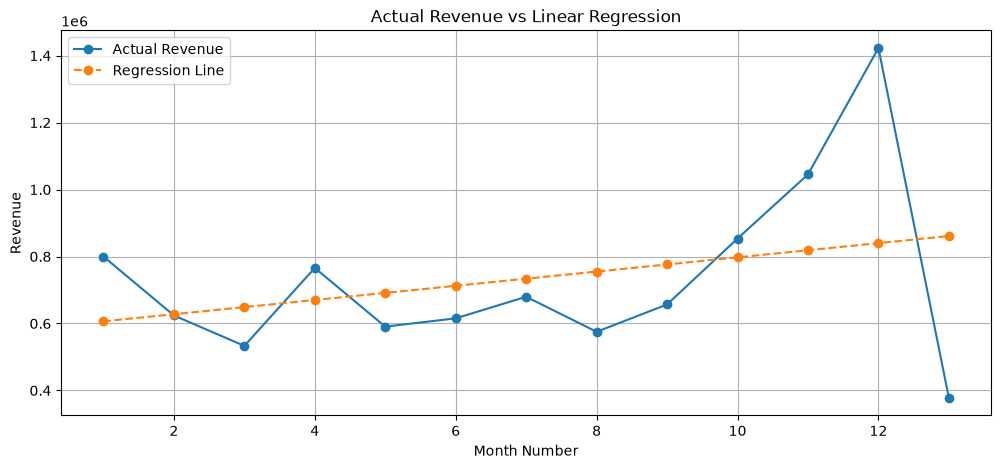

In [40]:
from sklearn.linear_model import LinearRegression
monthly_revenue=(df.groupby(df["InvoiceDate"].dt.to_period('M'))["TotalPrice"]).sum().reset_index()
print(monthly_revenue)
monthly_revenue["Month_No"]=range(1,len(monthly_revenue)+1)
print(monthly_revenue["Month_No"])
x=monthly_revenue[["Month_No"]]
y= monthly_revenue["TotalPrice"]

model = LinearRegression()
model.fit(x,y)
monthly_revenue["Predicted_Revenue"] = model.predict(x)
monthly_revenue["Revenue_Difference"] = (
    monthly_revenue["TotalPrice"].diff()
)
monthly_revenue["Revenue_Growth_Percentage"] = (
    monthly_revenue["TotalPrice"].pct_change() * 100
)

import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))


plt.plot(
    monthly_revenue["Month_No"],
    monthly_revenue["TotalPrice"],
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    monthly_revenue["Month_No"],
    monthly_revenue["Predicted_Revenue"],
    marker="o",
    linestyle="--",
    label="Regression Line"
)

plt.xlabel("Month Number")
plt.ylabel("Revenue")
plt.title("Actual Revenue vs Linear Regression")
plt.legend()
plt.grid()
plt.show()

In [34]:
!pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 2.4 MB/s eta 0:00:04
   ----- ---------------------------------- 1.3/9.3 MB 2.7 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.3 MB 2.9 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.3 MB 3.1 MB/s eta 0:00:03
   ---------------- ----------------------- 3.9/9.3 MB 3.4 MB/s eta 0:00:02
   -------------------- ------------------- 4.7/9.3 MB 3.5 MB/s eta 0:00:02
   ------------------------ --------------- 5.8/9.3 MB 3.7 MB/s eta 0:00:01
   ----------------------------- ---------- 6.8/9.3 MB 3.8 MB/s eta 0:00:01
   --------------------------------- ------ 7.9/9.3 MB 4.0 MB/s eta 0:00:01
   ---------------------------------------  9.2/